# Setup

In [29]:
# # Colab Setup
# !git clone https://github.com/fastai/course22p2.git
# %cd course22p2
# !pip install -q fastcore einops datasets timm
# import sys
# sys.path.append('/content/course22p2')
# !pip install -q k-diffusion fastcore einops datasets timm
# !pip install -q torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
# !pip install -q fastcore einops datasets timm k-diffusion
# !pip install -q torcheval fastcore einops datasets timm k-diffusion
# !pip install -q numpy==1.26.4 --force-reinstall

In [30]:
# Kaggle Setup
!git clone https://github.com/fastai/course22p2.git
!pip install -q numpy --upgrade          # upgrade numpy FIRST
!pip install -q fastcore einops datasets timm k-diffusion torcheval

fatal: destination path 'course22p2' already exists and is not an empty directory.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
dctorch 0.1.2 requires numpy<2.0.0,>=1.22.3, but you have numpy 2.4.6 which is incompatible.
ydata-profiling 4.18.4 requires numba<0.63,>=0.60, but you have numba 0.65.1 which is incompatible.
ydata-profiling 4.18.4 requires numpy<2.4,>=1.22, but you have numpy 2.4.6 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but

In [31]:
# Kaggle Setup
import sys
sys.path.append('/kaggle/working/course22p2')
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0,1'

In [32]:
import os
# os.environ['CUDA_VISIBLE_DEVICES']='1'

In [33]:
import timm, torch, random, datasets, math, fastcore.all as fc, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
import k_diffusion as K, torchvision.transforms as T
import torchvision.transforms.functional as TF,torch.nn.functional as F

from torch.utils.data import DataLoader,default_collate
from pathlib import Path
from torch.nn import init
from fastcore.foundation import L
from torch import nn,tensor
from datasets import load_dataset
from operator import itemgetter
from torcheval.metrics import MulticlassAccuracy,Mean,Metric
from functools import partial
from torch.optim import lr_scheduler
from torch import optim
from einops import rearrange

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.training import *
from miniai.init import *
from miniai.sgd import *
from miniai.resnet import *
from miniai.augment import *
from miniai.accel import *


torch.set_printoptions(precision=4, linewidth=140, sci_mode=False)
torch.manual_seed(1)
mpl.rcParams['image.cmap'] = 'gray_r'
mpl.rcParams['figure.dpi'] = 70

import logging
logging.disable(logging.WARNING)

# set_seed(42)
# if fc.defaults.cpus>8: fc.defaults.cpus=8

In [34]:
xl,yl = 'image','label'
name = "zalando-datasets/fashion_mnist"
bs = 256
dsd = load_dataset(name)

In [35]:
@inplace
def transformi(b):
    img = [TF.to_tensor(o).flatten() for o in b[xl]]
    b[yl] = b[xl] = img

tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=4)

In [36]:
dl = dls.valid
xb,yb = b = next(iter(dl))

# AutoEncoder

In [37]:
ni, nh, nl = 784, 400, 200

In [38]:
def lin(ni, nf, act=nn.SiLU, norm=nn.BatchNorm1d, bias=True):
  layers = nn.Sequential(nn.Linear(ni, nf, bias=bias))
  if act : layers.append(act())
  if norm : layers.append(norm(nf))
  return layers

In [39]:
def init_weights(m, leaky=0.):
  if isinstance(m, (nn.Conv1d,nn.Conv2d,nn.Conv3d,nn.Linear)): init.kaiming_normal_(m.weight, a=leaky)

- Because here it is almost that the entire network is `Linear_layers` so we make it well initialized also

In [40]:
iw = partial(init_weights, leaky=0.2)

In [41]:
class AutoEnc(nn.Module):
  def __init__(self, ni=ni, nh=nh, nl=nl):
    super().__init__()
    self.enc = nn.Sequential(lin(ni,nh), lin(nh,nh), lin(nh,nl))
    self.dec = nn.Sequential(lin(nl,nh), lin(nh,nh), lin(nh,ni, act=None))
    iw(self)
  def forward(self, x):
    return self.dec(self.enc(x))

In [42]:
opt_func = partial(optim.Adam, eps=1e-5)

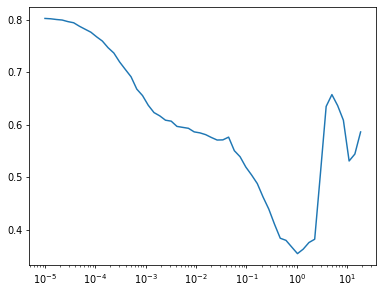

In [43]:
Learner(AutoEnc(), dls, nn.BCEWithLogitsLoss(), cbs=[DeviceCB(), MixedPrecision()], opt_func=opt_func).lr_find()

In [44]:
lr = 3e-2
epochs = 20
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched), MixedPrecision()]
model = AutoEnc()
learn = Learner(model, dls, nn.BCEWithLogitsLoss(), lr=lr, cbs=cbs, opt_func=opt_func)

    CROSS ENTROPY:
      loss = -[y·log(p) + (1-y)·log(1-p)]
      y=1 always (correct class)
      → (1-y) = 0, second term dies
      → loss = -log(p)
    

    BCE:
      same formula, but y can be 0 OR 1
      y=1: first term survives  → -log(p)
      y=0: second term survives → -log(1-p)
      - Two terms exist because y can be 0 OR 1.

    -WithLogits   → numerical safety because log(0)=-inf would explode

    BCELoss → YOU sigmoid first, then pass to loss (but has problem that
              log(0) can happen = -inf, or log(1.0) gradient dies —
              both caused by float rounding after sigmoid division)

    BCEWithLogitsLoss → pass raw logits, sigmoid happens INSIDE safely
                        (fixes both problems — same math but no division in sigmoid,
                        avoids float rounding entirely)

In [45]:
# learn.fit(epochs)

    loss	epoch	train
    0.527	0	train
    0.458	0	eval
    0.398	1	train
    0.352	1	eval
    0.316	2	train
    0.302	2	eval
    0.286	3	train
    0.284	3	eval
    0.276	4	train
    0.278	4	eval
    0.271	5	train
    0.273	5	eval
    0.268	6	train
    0.271	6	eval
    0.266	7	train
    0.269	7	eval
    0.265	8	train
    0.267	8	eval
    0.264	9	train
    0.266	9	eval
    0.263	10	train
    0.266	10	eval
    0.263	11	train
    0.265	11	eval
    0.262	12	train
    0.263	12	eval
    0.261	13	train
    0.262	13	eval
    0.261	14	train
    0.262	14	eval
    0.261	15	train
    0.261	15	eval
    0.260	16	train
    0.261	16	eval
    0.260	17	train
    0.261	17	eval
    0.260	18	train
    0.260	18	eval
    0.259	19	train
    0.260	19	eval


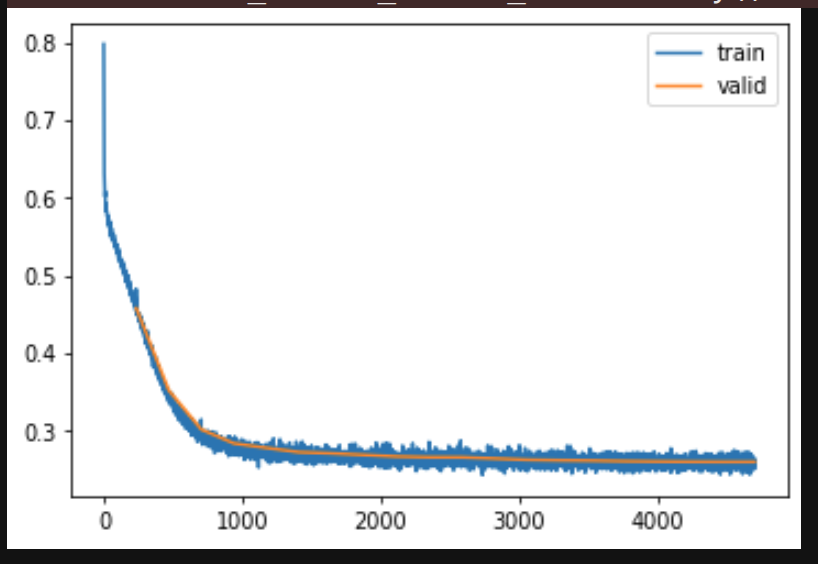


# Sampling

In [46]:
# with torch.no_grad(): t = to_cpu(model(xb.cuda()).float())

In [47]:
# show_images(xb[:9].reshape(-1,1,28,28), imsize=1.5, title='Original');

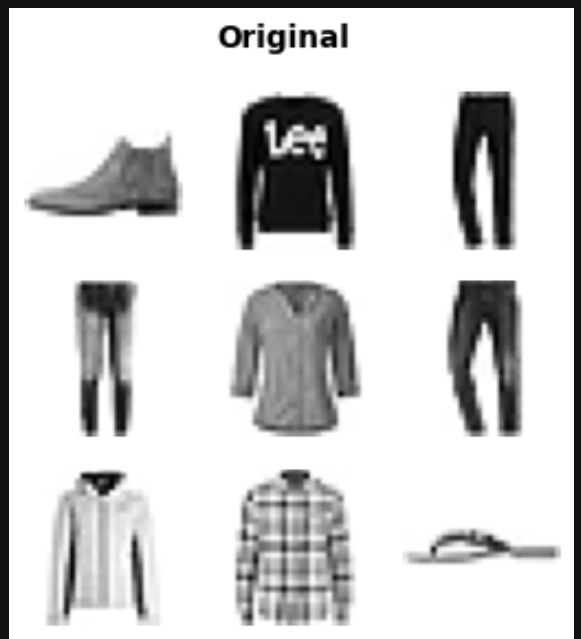


In [48]:
# show_images(t[:9].reshape(-1,1,28,28).sigmoid(), imsize=1.5, title='Autoenc');

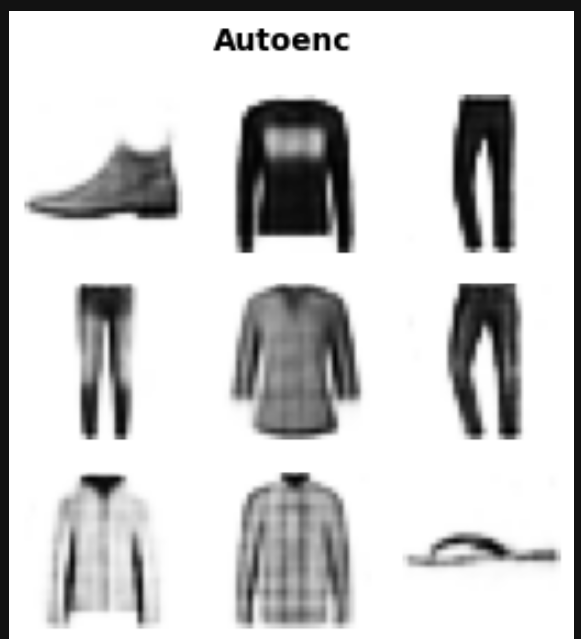


In [49]:
# # Lets try to make a generation from random latent
# noise = torch.randn(16, nl).cuda()
# with torch.no_grad(): generated_images = model.dec(noise).sigmoid()

In [50]:
# show_images(generated_images.reshape(-1, 1, 28, 28), imsize=1.5, title='Random Generation')

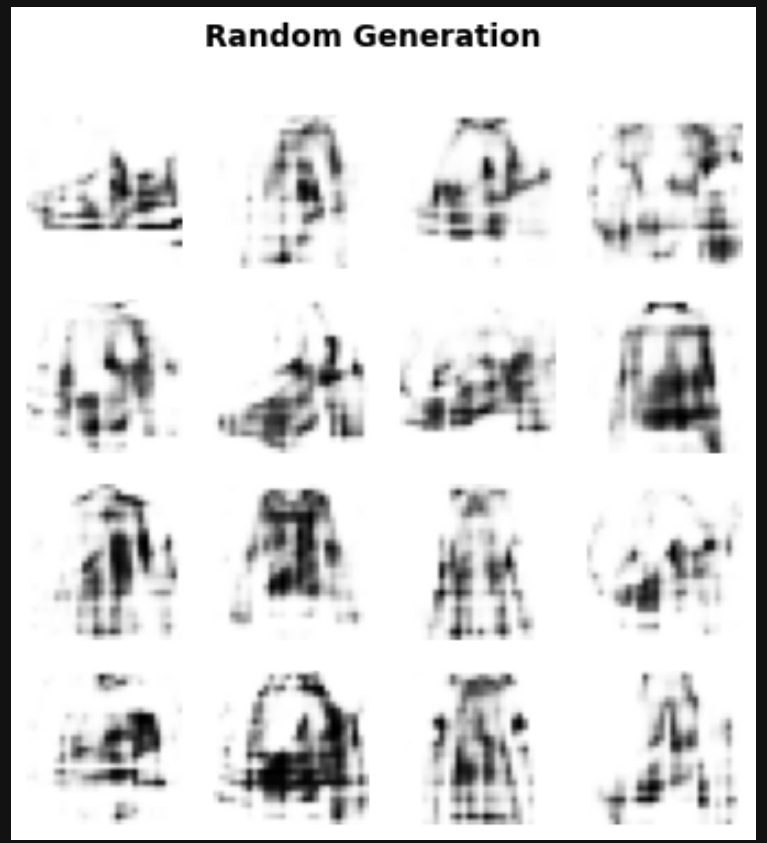


# VAE

In [51]:
class VAE(nn.Module):
  def __init__(self, ni=ni, nh=nh, nl=nl):
    super().__init__()
    self.enc = nn.Sequential(lin(ni,nh), lin(nh,nh))
    self.mu, self.lv = lin(nh,nl, act=None), lin(nh, nl, act=None)
    self.dec = nn.Sequential(lin(nl,nh), lin(nh,nh), lin(nh,ni,act=None))
    iw(self)

  def forward(self, x):
    x = self.enc(x)
    mu,lv = self.mu(x), self.lv(x)
    z = mu + (0.5*lv).exp()*torch.randn_like(lv)
    return self.dec(z), mu, lv  # return mu,lv is for the loss

   - `z = mu + (0.5*lv).exp()*torch.randn_like(lv)` So we add some randomness so that we can make it harder for the model which leads To having a more robust model Where we make the scaling so that balance
   - `exp(x) = e^x`

    VAE FINAL CONCLUSION
    ─────────────────────
    plain AE → one point per image → gaps in latent space → random sample = garbage
    VAE      → one BLOB per image → blobs overlap → random sample = valid image

    blob = Gaussian defined by two learnables:
      mu = center (where this class lives) [LEARNABLE]
      lv = spread (how wide the blob is) [LEARNABLE]

    0.5 is HARDCODED math, not a choice:
      convention: lv = log(variance)
      std = sqrt(variance) = exp(0.5 * lv)  ← 0.5 falls out of the definition
      if they defined lv = log(std) instead → exp(lv), no 0.5 needed

    lv never reaches 0 exactly:
      KLD wants lv=0, mu=0
      BCE needs mu≠0 to separate classes → mu never reaches 0 → lv never settles

    BCE:  pull blobs apart, shrink them    → accurate reconstruction
    KLD:  push everything toward N(0,1)   → no gaps, sampleable space
    both together → blobs small enough to mean something, close enough to overlap



    PLAIN AUTOENCODER:
    ──────────────────
      each image → encoder → ONE EXACT POINT

      latent space looks like this (2D for simplicity):

            0s cluster          7s cluster        3s cluster
                ●●●●                ●●                ●●●
                ●●●●                ●●                ●●●
                      GAP                  GAP

      the gaps = territory the decoder has NEVER seen
      you sample random point → lands in gap → decoder has no idea → garbage

    THE CORE PROBLEM:
    ──────────────────
    - a point has no size
    - sampling randomly almost never hits an exact point
    - you need the clusters to have SIZE and to be CONNECTED

    VAE — the fix:
    ───────────────
    instead of mapping image → one point
    map image → a BLOB (a Gaussian)

      same latent space now:

            0s blob             7s blob           3s blob
            ░░░░░░░░          ░░░░░░░░          ░░░░░░░░
            ░░████░░          ░░████░░          ░░████░░
            ░░░░░░░░          ░░░░░░░░          ░░░░░░░░

      ████ = center (mu)
      ░░░░ = spread (sigma)

      during training: z is sampled from ANYWHERE in the blob
      decoder learns to handle the whole blob, not just the center
    KLD'S ONLY JOB:
    ────────────────
    pull all blobs toward the origin, so they're close enough to overlap

      without KLD:             with KLD:

      0s●●●  gap  7s●●●        0s░░░░7s░░░░3s░░░░
      
      blobs far apart          blobs close, edges overlapping
      still has gaps           no gaps anywhere near origin

      now: sample from N(0,1) → always lands in SOME blob's territory
          decoder has seen that territory → valid image comes out
    SO WHAT ARE mu AND lv ACTUALLY DOING?
    ───────────────────────────────────────
    mu  = where is the CENTER of this image's blob
          7s live in one direction, 0s in another
          they're different but both close to origin (KLD won't let them go far)

    lv  = how BIG is the blob
          too small → blob is a point → gaps come back → random sample fails
          too big   → blob covers everything → decoder can't tell 7 from 0
          KLD forces blob size toward variance=1 → right size automatically
    GENERATION — why it works now:
    ───────────────────────────────
    sample z ~ N(0,1)
    → lands somewhere near origin
    → origin is where ALL the overlapping blobs live
    → decoder was trained on every point in every blob
    → decoder knows exactly what to output
    → valid image

    the specific z you sample determines which "neighborhood" you land in
    → different z = different digit, different style, smooth transitions

In [52]:
def kld_loss(inp, x):
  x_hat,mu,lv = inp
  return -0.5 * (1 + lv - mu.pow(2) - lv.exp()).mean()
def bce_loss(inp, x): return F.binary_cross_entropy_with_logits(inp[0], x)
def vae_loss(inp, x): return kld_loss(inp,x) + bce_loss(inp,x)

    EXTRA INFO THAT DOESNT MATTER MUCH

    for lv — that's the full loop:

      KLD needs: log(variance) and variance directly in its formula
      we define: lv = log(variance)
      plugs in:  lv → log(variance) term, exp(lv) → variance term
      model has no choice: learn values that behave like log(variance) to minimize KLD

      the convention and the loss are locked together
      one without the other breaks
    FOR mu — same loop but simpler:

      KLD needs: mu directly (mu² term)
      no transformation needed — mu just plugs straight in as itself
      model has no choice: learn values that behave like a mean
      or mu² term in KLD to minimize it and prevent KLD explosion


    FULL LOOP ONE LINE:
      KLD defines what mu and lv must be
      BCE makes them actually useful
      the model learns both under that pressure — no other option

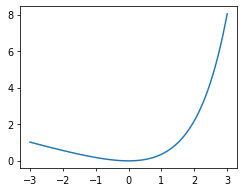

In [53]:
x = torch.linspace(-3,3,100)
plt.figure(figsize=(4,3))
plt.plot(x, -0.5*(1+x-x.exp()));

In [54]:
class FuncMetric(Mean):
  def __init__(self, fn, device=None):
    super().__init__(device=device)
    self.fn = fn

  def update(self, inp, targs):
    self.weighted_sum += self.fn(inp, targs)
    self.weights +=1

    FuncMetric
    ───────────
    Mean parent tracks: weighted_sum / weights = average over batches
    both reset to 0 at START of each epoch → fresh average per epoch

    FuncMetric.update():
      weighted_sum += fn(inp, targs)   # accumulate kld or bce loss
      weights += 1                      # count batches

    MetricsCB(kld=FuncMetric(kld_loss), bce=FuncMetric(bce_loss))
    → tracks each loss component separately, displays as own column

    FuncMetric is ONLY for display — has zero effect on training
    actual training loss (backprop): vae_loss computed fresh each batch

    table:  loss = kld + bce every row  (0.430 + 0.546 = 0.976 ✓)

    what actually happens:
      1. forward pass: model(xb) → preds (stored on learner)
      2. vae_loss(preds, yb) → backprop → weights update
      3. MetricsCB.after_batch() takes the ALREADY STORED preds
         and calls kld_loss(preds, yb) and bce_loss(preds, yb) separately
         → no second forward pass, just re-using stored outputs

In [55]:
metrics = MetricsCB(kld=FuncMetric(kld_loss), bce=FuncMetric(bce_loss))
opt_func = partial(optim.Adam, eps=1e-5)

In [58]:
lr = 3e-2
epochs = 20
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), ProgressCB(plot=True), metrics, BatchSchedCB(sched), MixedPrecision()]
model = VAE()
learn = Learner(model, dls, vae_loss, lr=lr, cbs=cbs, opt_func=opt_func)

kld,bce,loss,epoch,train
0.430,0.546,0.977,0,train
0.322,0.497,0.818,0,eval
0.100,0.445,0.545,1,train
0.045,0.406,0.451,1,eval
0.034,0.383,0.417,2,train
0.037,0.363,0.400,2,eval
0.035,0.356,0.391,3,train
0.038,0.349,0.388,3,eval
0.036,0.348,0.384,4,train
0.037,0.345,0.382,4,eval


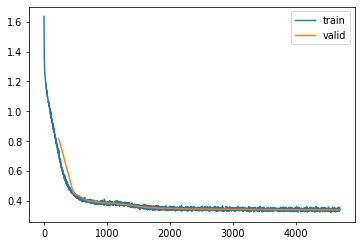

In [59]:
learn.fit(epochs)

# Sampling

In [60]:
with torch.no_grad(): p,mu,lv = to_cpu(model(xb.cuda()))
p = p.float()

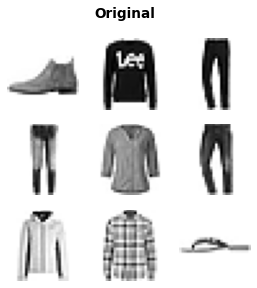

In [61]:
show_images(xb[:9].reshape(-1,1,28,28), imsize=1.5, title='Original');

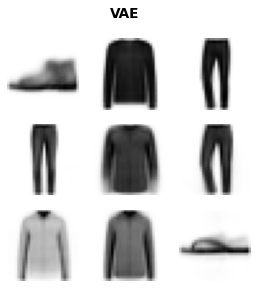

In [62]:
show_images(p[:9].reshape(-1,1,28,28).sigmoid(), imsize=1.5, title='VAE');

In [63]:
noise = torch.randn(16, nl).cuda()
with torch.no_grad(): ims = model.dec(noise).sigmoid()

In [64]:
ims.shape

torch.Size([16, 784])

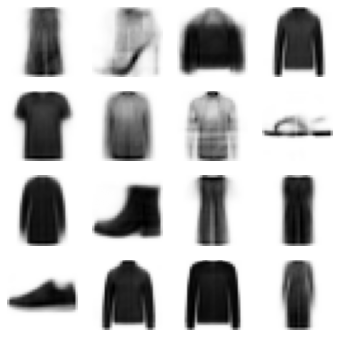

In [65]:
show_images(ims.reshape(-1, 1, 28, 28), imsize=1.5)

It is worse at regenerating images, but better at generating from noise